# Frente B, capítulo 4: filtrado espacial CSP (etapa 8)

**Módulo:** `descriptores/csp.py` · **Figuras:** `b_csp_*`

## De qué se trata

Hasta acá cada canal de EEG se analizó por separado. Pero los cuatro canales (F4, C4,
O2 y C3) miran zonas distintas del cerebro, y lo que distingue a dos estadios puede
estar en **cómo se reparte la actividad entre zonas** más que en un canal suelto.

Los **patrones espaciales comunes** (CSP, técnica no vista en clase) buscan la suma
ponderada de los cuatro canales cuya potencia sea lo más grande posible en un estadio y
lo más chica posible en otro. Se aplica al par que más se confunde, **N1 y REM**, que
tienen un EEG muy parecido canal por canal.

## El recorrido de la señal

```
EEG de los 4 canales, cada época
   │
   ├─ matriz de covarianza 4 × 4 de la época          covarianzas_por_epoca()
   │     (queda guardada en la tabla de descriptores)
   │
   ├─ covarianza media de N1 y de REM, con los pacientes de entrenamiento
   ├─ autovalores generalizados: pesos de cada canal  ajustar_csp()
   │
   └─ log-potencia de la señal combinada, por época   aplicar_csp()
```

CSP es la única etapa del Frente B que usa las etiquetas de los técnicos. Por eso no se
calcula al describir cada registro: el modelo del Frente C la ajusta solo con los
pacientes de entrenamiento y la usa para desempatar N1 y REM.

## Entorno y datos

Los resultados de abajo se calcularon con un registro real de la base, SN122 (un
paciente de entrenamiento), y los números del texto son de ese paciente. Si no hay datos descargados, el notebook usa el registro
sintético de `comun/sintetico.py` y las figuras cambian.

Las señales llegan **preprocesadas** por el Frente A (`pipeline.preprocesar`): filtradas
entre 0,2 y 45 Hz con notch en 50 Hz, sin artefacto ocular (Wiener con compuerta) y sin
artefacto cardíaco. El EMG va con un pasa-altos de 10 Hz. La señal cruda queda en
`crudo` para comparar.

In [1]:
# Entorno común a todos los notebooks: se corre desde codigo/ para que DIR_DATOS
# ("data" o $ESTADIOS_DATOS) apunte al mismo lugar que los scripts.
import os
import sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

# Si el paquete no está instalado con `pip install -e .`, se usa directamente codigo/src.
# Las dependencias (numpy, scipy, pandas, matplotlib, mne) sí tienen que estar
# instaladas en el Python de este kernel.
try:
    import estadios  # noqa: F401
except ModuleNotFoundError:
    sys.path.insert(0, str(Path.cwd() / "src"))
FIGURAS = Path.cwd().parent / "informe" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt

from estadios.comun.config import Config
from estadios.comun.constantes import NOMBRES_ESTADIOS, N_ESTADIOS
from estadios.datos.carga import ids_disponibles

USAR_DATOS_REALES = len(ids_disponibles()) > 0
print("Datos reales" if USAR_DATOS_REALES else "Sin datos descargados: se usan los sintéticos")

Datos reales


In [2]:
# Estilo común de las figuras del Frente B. Cada estadio tiene siempre el mismo color.
COLOR_ESTADIO = dict(zip(NOMBRES_ESTADIOS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
AZUL, NARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"
GRIS, TINTA = "#8a8984", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRIS,
    "axes.labelcolor": TINTA,
    "axes.titlesize": 10,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "xtick.color": TINTA,
    "ytick.color": TINTA,
    "lines.linewidth": 1.5,
    "legend.frameon": False,
})


def guardar(fig, nombre):
    """Guarda la figura en informe/figuras/ para incluirla con \\includegraphics."""
    fig.savefig(FIGURAS / f"{nombre}.pdf", bbox_inches="tight")


def por_estadio(ax, valores, estadios, titulo, unidad=""):
    """Diagrama de caja de un descriptor en cada estadio, sin los valores extremos."""
    grupos = [valores[estadios == e] for e in range(N_ESTADIOS)]
    cajas = ax.boxplot(grupos, tick_labels=NOMBRES_ESTADIOS, showfliers=False,
                       patch_artist=True, widths=0.55,
                       medianprops={"color": TINTA, "linewidth": 1.5})
    for caja, nombre in zip(cajas["boxes"], NOMBRES_ESTADIOS):
        caja.set(facecolor=COLOR_ESTADIO[nombre], alpha=0.55, edgecolor=GRIS)
    ax.set(title=titulo, ylabel=unidad)
    ax.grid(axis="x", visible=False)

In [3]:
from estadios.comun.sintetico import preprocesado_sintetico
from estadios.datos.carga import cargar_registro
from estadios.pipeline import preprocesar

cfg = Config().descriptores
if USAR_DATOS_REALES:
    # La señal cruda se guarda para comparar; los descriptores usan la preprocesada.
    # SN122 es el paciente de ejemplo de los textos; si no está, se usa el primero.
    disponibles = ids_disponibles()
    crudo = cargar_registro("SN122" if "SN122" in disponibles else disponibles[0])
    prep = preprocesar(crudo, Config().preprocesamiento)
else:
    prep = preprocesado_sintetico(minutos=120)
    crudo = prep.registro

registro = prep.registro
fs = registro.fs
estadios_tecnicos = registro.estadios
print(f"{registro.id}: {registro.n_epocas} épocas de 30 s ({registro.n_epocas / 120:.1f} h)")
print({n: int((estadios_tecnicos == e).sum()) for e, n in enumerate(NOMBRES_ESTADIOS)})

SN122: 845 épocas de 30 s (7.0 h)
{'W': 66, 'N1': 67, 'N2': 303, 'N3': 288, 'R': 121}


## 1. La covarianza de cada época

Para cada época se calcula la matriz de covarianza de los cuatro canales. En su diagonal
está la potencia de cada canal, y fuera de ella cuánto varían juntos dos canales.

La potencia de cualquier combinación de canales sale directamente de esa matriz. Si la
señal combinada es $s(t) = \mathbf{w}^\top \mathbf{x}(t)$, con $\mathbf{w}$ los cuatro
pesos y $\mathbf{x}(t)$ los cuatro canales, su potencia en la época es
$\mathbf{w}^\top \mathbf{C}\, \mathbf{w}$. Por eso alcanza con guardar las covarianzas en
la tabla: CSP se puede ajustar y aplicar después sin volver a leer las señales.

In [4]:
from estadios.comun.constantes import CANALES_EEG, N1, R
from estadios.descriptores import csp
from estadios.preprocesamiento.segmentacion import segmentar

epocas_eeg = segmentar(registro.eeg(), fs, registro.n_epocas)
covarianzas = csp.covarianzas_por_epoca(epocas_eeg)
print(f"Covarianzas: {covarianzas.shape} (épocas × canales × canales)")
print("Una época de N1, en µV²:")
print(np.round(covarianzas[np.flatnonzero(estadios_tecnicos == N1)[0]], 1))

Covarianzas: (845, 4, 4) (épocas × canales × canales)
Una época de N1, en µV²:
[[175.9 154.9  42.  113.5]
 [154.9 200.7  59.3 163. ]
 [ 42.   59.3 162.3  18.6]
 [113.5 163.   18.6 192.8]]


## 2. Los pesos: un problema de autovalores

Se calcula la covarianza media de las épocas de N1, $\mathbf{C}_{N1}$, y la de REM,
$\mathbf{C}_{R}$. Antes de promediar, cada matriz se divide por su traza (la potencia
total de la época), para que no dominen las épocas de mayor amplitud.

Los pesos buscados son los que hacen máximo, o mínimo, el cociente

$$\lambda = \frac{\mathbf{w}^\top \mathbf{C}_{N1}\, \mathbf{w}}{\mathbf{w}^\top (\mathbf{C}_{N1} + \mathbf{C}_{R})\, \mathbf{w}},$$

que es la fracción de la potencia de la señal combinada que corresponde a N1. Esos
pesos son los autovectores del problema generalizado
$\mathbf{C}_{N1}\mathbf{w} = \lambda\, (\mathbf{C}_{N1} + \mathbf{C}_{R})\, \mathbf{w}$, que
`scipy.linalg.eigh` resuelve en un solo paso, sin iteraciones.

- El autovector con $\lambda$ cerca de 1 da una señal con mucha potencia en N1 y poca
  en REM.
- El de $\lambda$ cerca de 0, lo contrario.

Se quedan los dos filtros de cada extremo: cuatro en total.

En este notebook CSP se ajusta con todas las épocas de **este** registro, solo para
mostrar cómo funciona. En el modelo real se ajusta con los pacientes de entrenamiento.

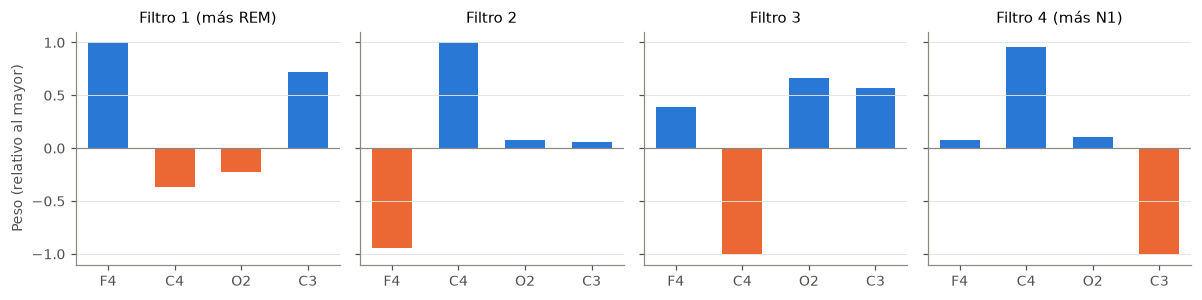

In [5]:
par = (N1, R)
filtro = csp.ajustar_csp(covarianzas, estadios_tecnicos, par, Config().clasificacion.componentes_csp)
etiquetas = ["Filtro 1 (más REM)", "Filtro 2", "Filtro 3", "Filtro 4 (más N1)"]
canales = [c.split()[1].split("-")[0] for c in CANALES_EEG]

fig, axs = plt.subplots(1, 4, figsize=(11, 2.8), sharey=True)
for ax, pesos, titulo in zip(axs, filtro.pesos, etiquetas):
    pesos = pesos / np.abs(pesos).max()  # El signo y la escala de un autovector son arbitrarios.
    ax.bar(canales, pesos, color=[AZUL if p >= 0 else NARANJA for p in pesos], width=0.6)
    ax.axhline(0, color=GRIS, lw=0.8)
    ax.set(title=titulo)
    ax.grid(axis="x", visible=False)
axs[0].set(ylabel="Peso (relativo al mayor)")
fig.tight_layout()
guardar(fig, "b_csp_pesos")

Cada panel muestra cómo combina los cuatro canales un filtro. Un peso positivo suma el
canal y uno negativo lo resta. Restar dos canales cancela lo que tienen en común, así
que un filtro con pesos de signo opuesto resalta las **diferencias** entre zonas. Hay
que leer los pesos con cuidado: indican cómo se combinan los canales para separar los
estadios, no directamente qué zona está más activa.

## 3. ¿Separa N1 de REM?

`aplicar_csp()` calcula, para cada época, el logaritmo de la potencia de cada señal
combinada, $\log(\mathbf{w}^\top \mathbf{C}\, \mathbf{w})$. La figura compara esa
log-potencia en las épocas de N1 y de REM, para los dos filtros de los extremos.

Filtro 1 (más REM): mediana N1 = 6.14, mediana REM = 6.17
Filtro 4 (más N1): mediana N1 = 6.43, mediana REM = 5.58


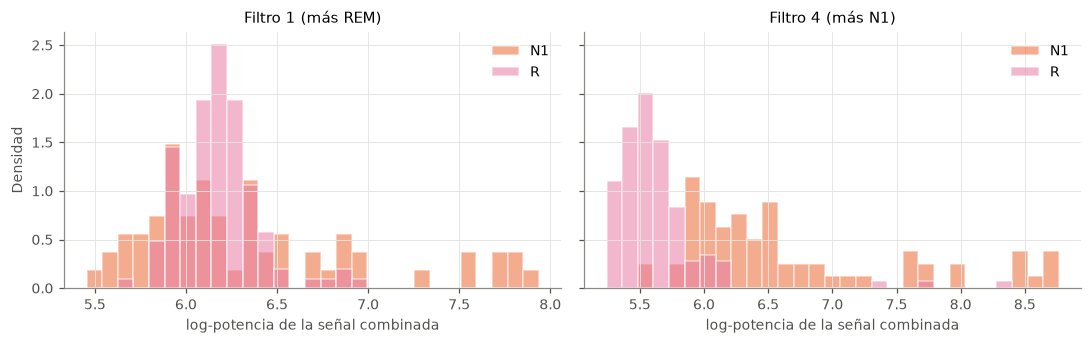

In [6]:
potencias = csp.aplicar_csp(covarianzas, filtro)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, columna in zip(axs, [0, len(filtro.pesos) - 1]):
    valores = potencias[:, columna]
    bins = np.linspace(*np.percentile(valores[np.isin(estadios_tecnicos, par)], [1, 99]), 30)
    for estadio, nombre in [(N1, "N1"), (R, "R")]:
        ax.hist(valores[estadios_tecnicos == estadio], bins, density=True, alpha=0.55,
                color=COLOR_ESTADIO[nombre], label=nombre, edgecolor="white")
    ax.set(title=etiquetas[columna], xlabel="log-potencia de la señal combinada")
    ax.legend()
axs[0].set(ylabel="Densidad")
fig.tight_layout()
guardar(fig, "b_csp_separacion")

for columna in [0, len(filtro.pesos) - 1]:
    m_n1, m_r = (np.median(potencias[estadios_tecnicos == e, columna]) for e in par)
    print(f"{etiquetas[columna]}: mediana N1 = {m_n1:.2f}, mediana REM = {m_r:.2f}")

Los dos estadios se superponen, porque N1 y REM son realmente parecidos. En el filtro 4
la separación es clara: las épocas de REM se juntan en valores bajos y las de N1 se
reparten hacia valores más altos. En el filtro 1 la diferencia apenas se nota, así que
en este registro casi toda la información está en un extremo. Ese corrimiento es lo que usa el
Frente C para cambiar una época de N1 a REM, o al revés, solo cuando la evidencia es
clara. Si eso mejora la clasificación de N1 y REM es la hipótesis H3, que se prueba en
el notebook 04.

## 4. Lo que sale de este capítulo

El Frente B entrega las covarianzas de cada época en `TablaDescriptores.covarianzas_eeg`.
Los descriptores `csp.*` los agrega el modelo del Frente C después de ajustar los
filtros con los pacientes de entrenamiento.